## Description
This notebook generates visualizations and outputs them to results/visualisations to better understand how the model results come about. It is structured like:
1. Imports
2. Loading model runs
2. Setting technology colors for some visualisations
3. All functions
5. Inspecting results and using of functions for visualisations

### 1) Imports

In [1]:
from pathlib import Path
import re
import warnings
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import pypsa
from IPython.display import display

years = [2020, 2030, 2040, 2050]


### 2) Load networks

In [33]:
RESULTS_DIR = Path("results/temporal_scenarios")
SCENARIOS = ["default_tech_low_carbon", "default_tech_high_carbon", "improved_tech_low_carbon", "improved_tech_high_carbon"]
LABELS = {
    "default_tech_low_carbon": "Default technology | default CO₂ price (S1)",
    "default_tech_high_carbon": "Default technology | high CO₂ price (S2)",
    "improved_tech_low_carbon": "Improved technology | default CO₂ price (S3)",
    "improved_tech_high_carbon": "Improved technology | high CO₂ price (S4)",
}

networks = {}
for scenario in SCENARIOS:
    file = RESULTS_DIR / f"{scenario}.nc"
    if not file.exists():
        raise FileNotFoundError(f"Missing scenario result: {file}")
    networks[scenario] = pypsa.Network(str(file))

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'default_tech_low_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'default_tech_high_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'improved_tech_low_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'improved_tech_high_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


In [3]:
tech_colors = {
    # Electricity generation
    "CCGT": "#E68127",                         # Orange
    "CCGT - existing": "#F5B97D",              # Light orange
    "CCGT CCS": "#A84B0F",                     # Burnt orange
    "Biomass plant": "#7CAD45",                # Leaf green
    "Biomass plant CCS": "#276339",            # Dark green
    "Nuclear plant": "#8C58B5",                # Purple
    "Solar": "#E9C52B",                        # Golden yellow
    "Wind onshore": "#37B9AA",                 # Turquoise
    "Wind offshore": "#087F86",                # Deep teal


    # Transport
    "BEV": "#4779D1",                          # Blue
    "BEV - existing": "#A5BEF0",               # Light blue
    "ICE car": "#BC6951",                      # Terracotta
    "ICE car - existing": "#E5AE9D",           # Light terracotta

    # Electricity storage
    "Battery": "#483A88",                      # Indigo

    # Residential demand and heating
    "Residential Appliance": "#737D8C",        # Slate grey
    "Residential gas boiler": "#D8A026",       # Ochre
    "Residential gas boiler - existing": "#EFD18B",
    "Residential heat pump": "#56B5E4",        # Sky blue

    # Large-scale heating
    "Large-scale heat pump": "#008EB8",        # Cyan blue
    "Large-scale heat pump - existing": "#8DD5E7",

    # Industrial boilers
    "Industrial gas boiler": "#A88B55",        # Sand brown
    "Industrial gas boiler - existing": "#D8C7A5",

    # Industrial machinery
    "Industrial machinery - fossil": "#996343",
    "Industrial machinery - fossil - existing": "#CDAF94",
    "Industrial machinery - fossil CCS": "#593B27",
    "Industrial machinery - electricity": "#234D96",

    # Industrial high-temperature processes
    "Industrial HTP - fossil": "#B44742",      # Brick red
    "Industrial HTP - fossil - existing": "#DD9692",
    "Industrial HTP - fossil CCS": "#702C36",  # Burgundy

    # Hydrogen production
    "SMR": "#CC743D",                         # Copper
    "SMR - existing": "#E8B79C",
    "SMR with CCS": "#80532B",                # Bronze
    "SMR with CCS - existing": "#BCA07D",
    "Electrolysis": "#7166CF",                # Blue-violet
    "Electrolysis - existing": "#B9B2EB",

    # Emissions
    "CO2 atmosphere": "#333333",              # Charcoal
}

# Alternative names used in your original dictionary.
tech_colors.update({
    "Solar PV": tech_colors["Solar"],
    "Wind turbine - onshore": tech_colors["Wind onshore"],
    "Wind turbine - offshore": tech_colors["Wind offshore"],
})

tech_colors.update({
    # Electricity generation
    "Biomass plant CCS": "#228833",       # Green
    "CCGT": "#F57900",                    # Orange
    "CCGT - existing": "#FFC180",         # Light orange
    "CCGT CCS": "#8C510A",                # Dark brown

    # Emissions
    "CO2 atmosphere": "#333333",          # Charcoal

    # Transport
    "ICE car": "#0077BB",                 # Blue
    "ICE car - existing": "#91C9EB",       # Light blue

    # Industrial high-temperature processes
    "Industrial HTP - fossil": "#CC3311",                 # Vermilion
    "Industrial HTP - fossil - existing": "#F3A18D",      # Light salmon
    "Industrial HTP - fossil CCS": "#882255",             # Burgundy

    # Industrial low-temperature heating
    "Industrial gas boiler": "#AA4499",                  # Purple
    "Industrial gas boiler - existing": "#D8ACD0",       # Light purple

    # Industrial machinery
    "Industrial machinery - fossil": "#008878",          # Teal
    "Industrial machinery - fossil - existing": "#8CD3C7",  # Light teal
    "Industrial machinery - fossil CCS": "#004C46",      # Dark teal

    # Residential heating
    "Residential gas boiler": "#D4AA00",                 # Mustard
    "Residential gas boiler - existing": "#F5DF87",       # Light yellow

    # Hydrogen production
    "SMR": "#6655CC",                     # Violet
    "SMR - existing": "#BDB3EA",          # Light violet
    "SMR with CCS": "#596B28",            # Olive
    "SMR with CCS - existing": "#BCC995", # Light olive
})


### 3) Orienting to model results using energy balances

In [20]:
# Handy plotting functions. 
# Note that these are good to quickly diagnose your runs, 
# but for your final presentation and paper you will need
# nicer-looking plots, following the data-visualization 
# guidelines we discussed in class!

def plot_main_ebs_complete(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Residential heat',
            'Transportation',
            'Industrial machinery',
            'Industrial HTP',
            'Industrial LTP',]): 
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar',stacked='True', rot=0, colormap="tab20",ax=ax[n])
        if c=='Transportation':
            ax[n].set_ylabel('Mvkm')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)

    fig.tight_layout()

def plot_elc_emi(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Electricity','CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar',stacked='True', rot=0, colormap="tab20", ax=ax[n])

        if 'CO2' in c:
            ax[n].set_ylabel('tCO2')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)
        ax[n].legend(bbox_to_anchor=(1,-0.5))

    # Let's add cumulative CO2
    for n,c in enumerate(['CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c).cumsum(axis=1)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar', stacked=True, colormap='tab20', ax=ax[n+3])
        ax[n+3].set_ylabel('tCO2')
        ax[n+3].set_title(f'Cumulative {c}')
        ax[n+3].legend(bbox_to_anchor=(1,-0.5))

    fig.tight_layout()


default_tech_low_carbon


/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_32642/342269979.py:52: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


improved_tech_low_carbon


/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_32642/342269979.py:52: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


default_tech_high_carbon


/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_32642/342269979.py:52: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


improved_tech_high_carbon


/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_32642/342269979.py:52: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


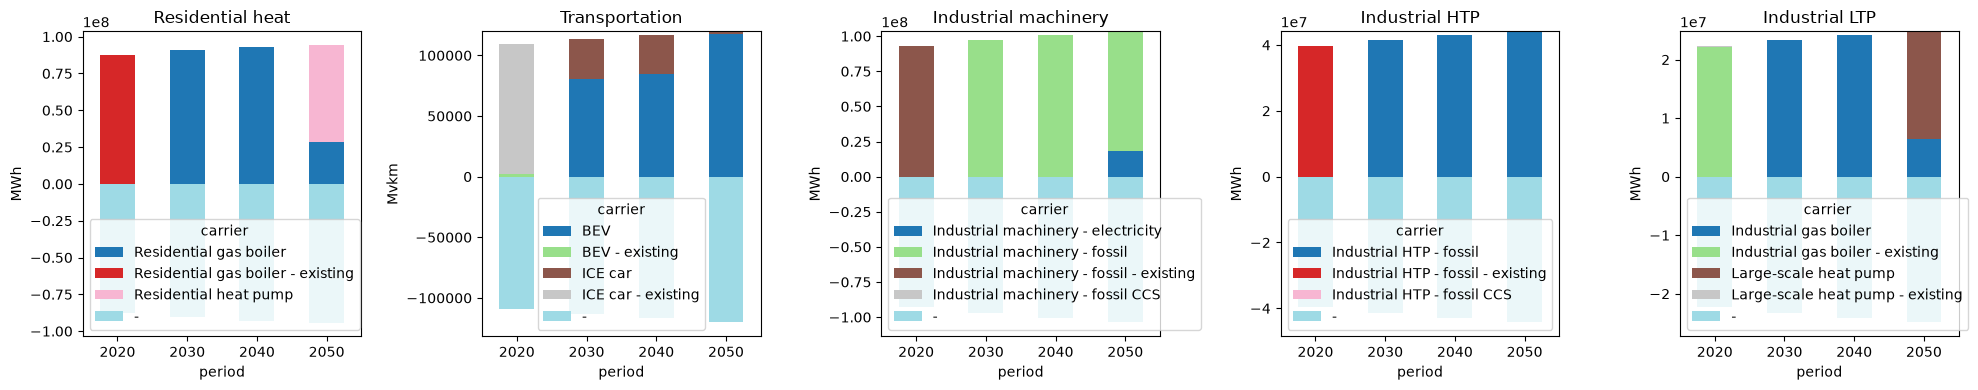

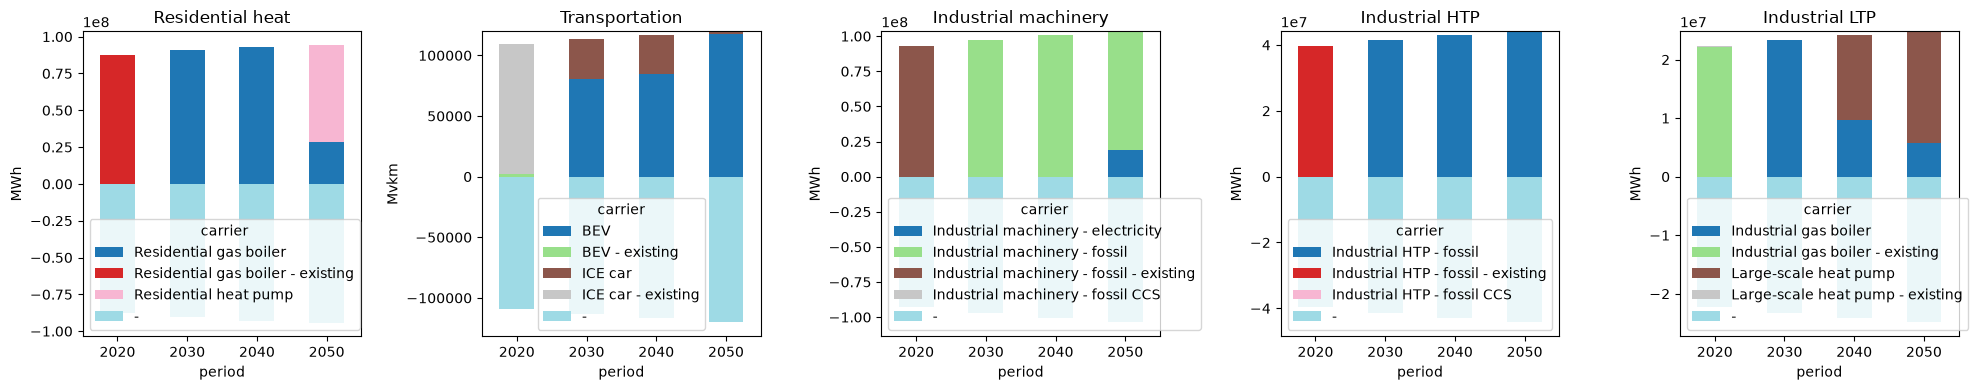

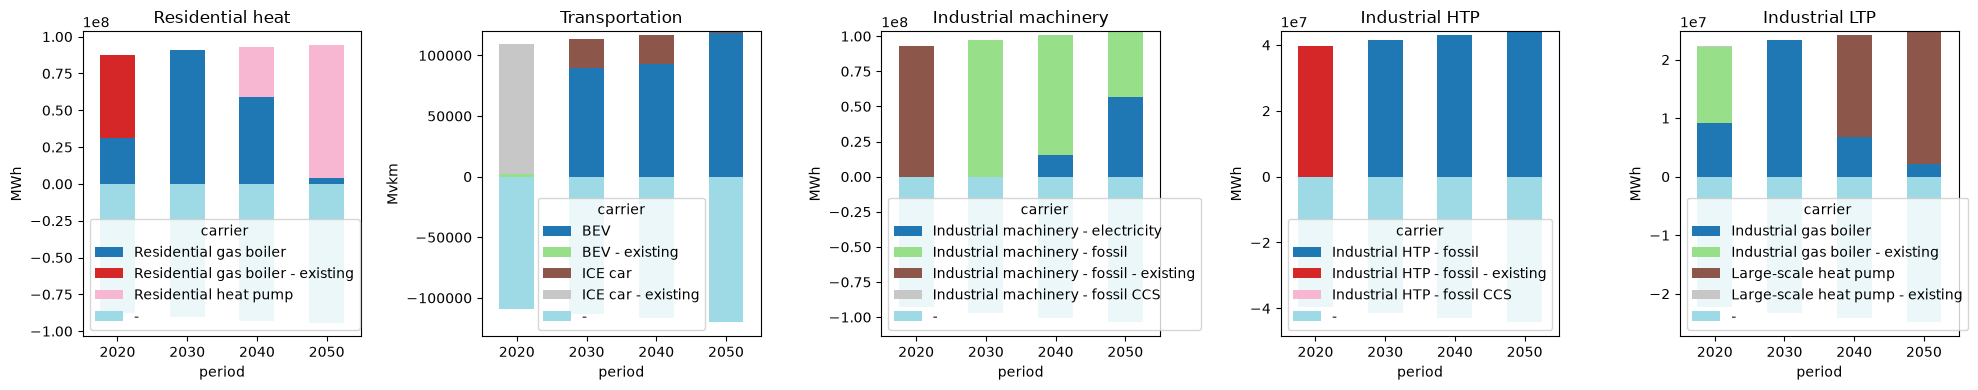

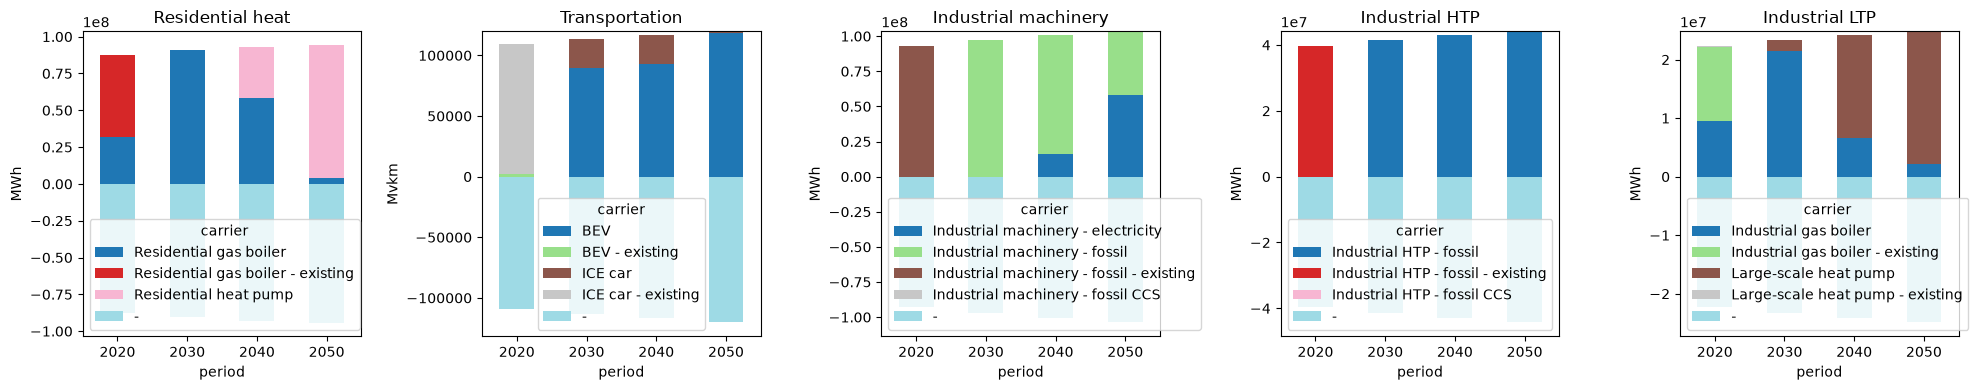

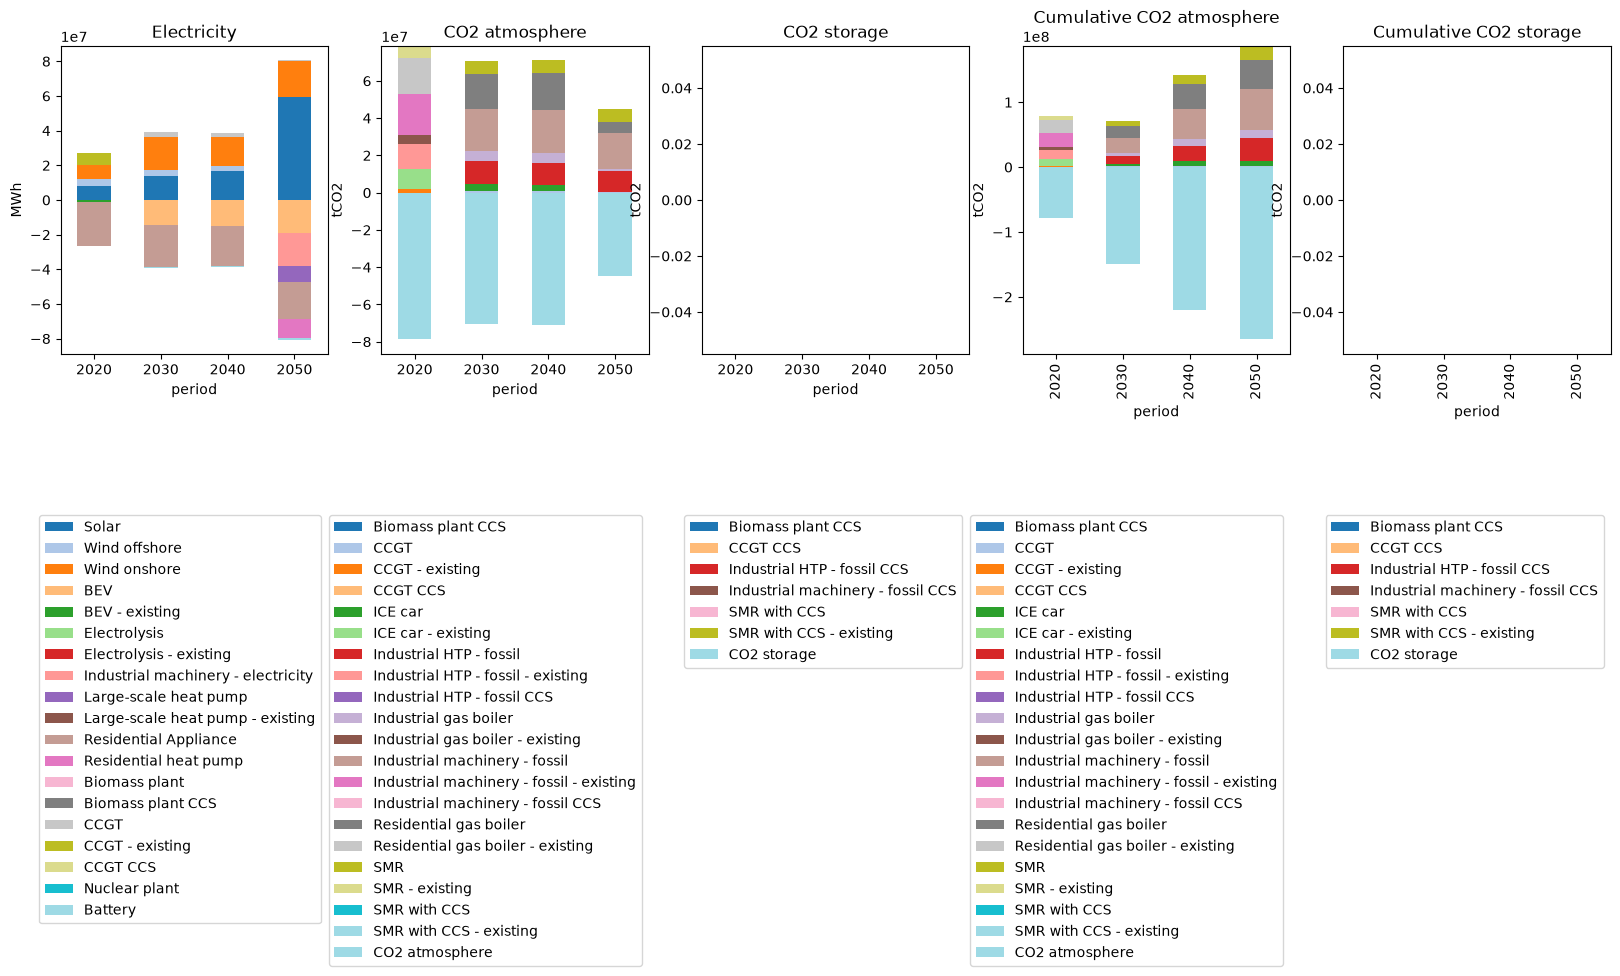

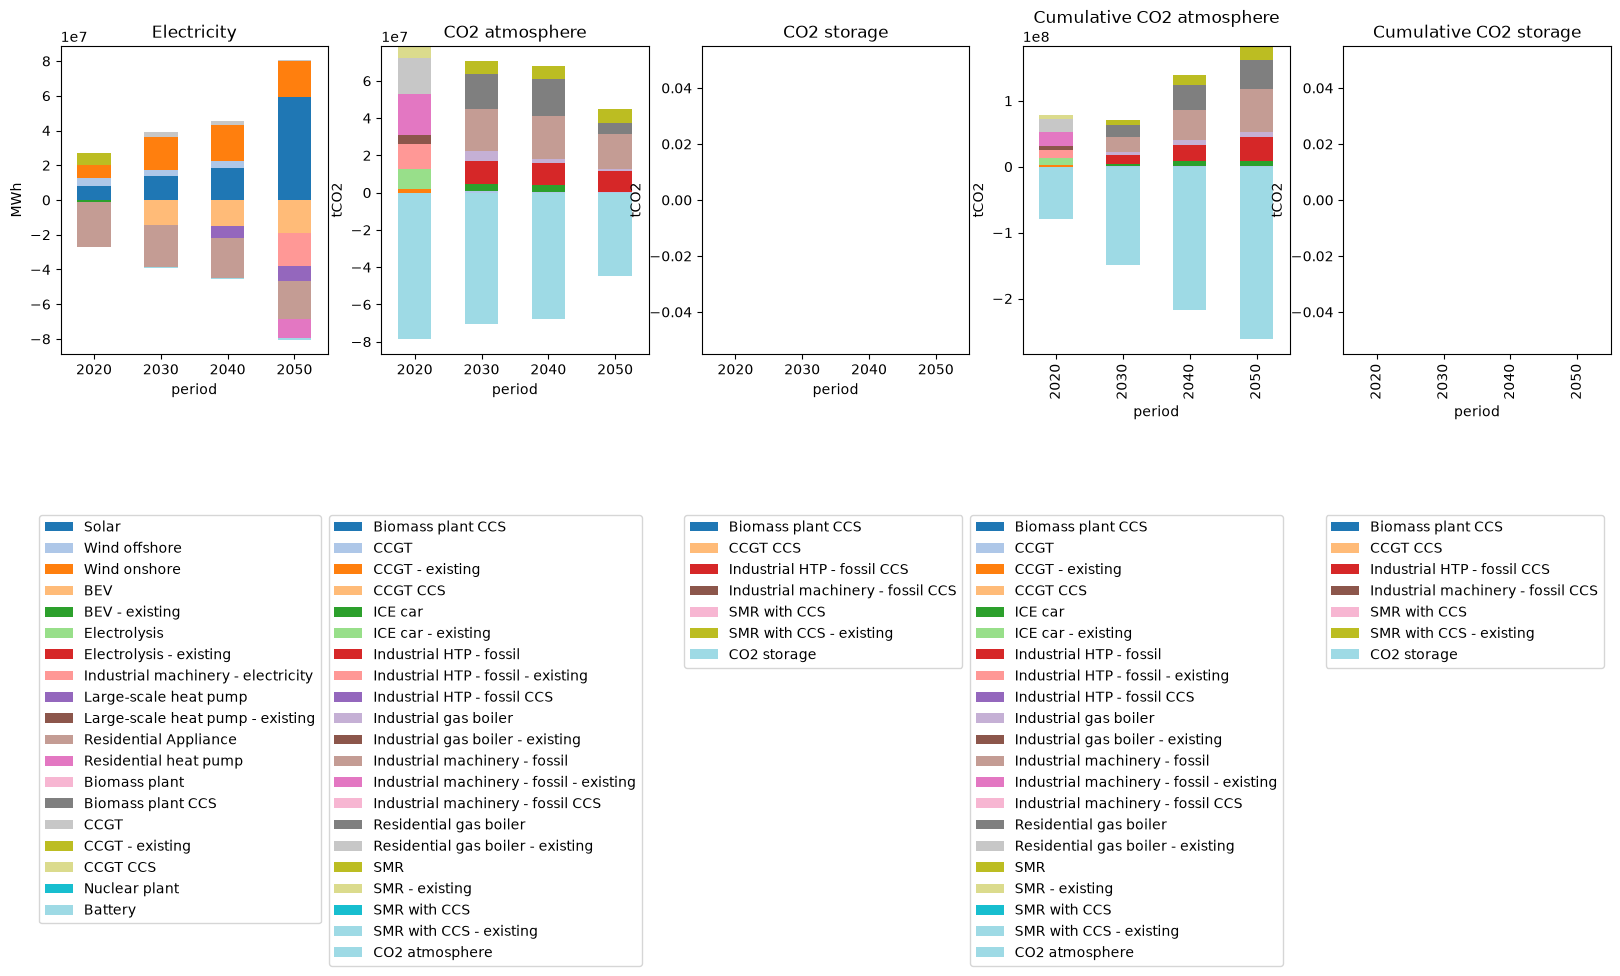

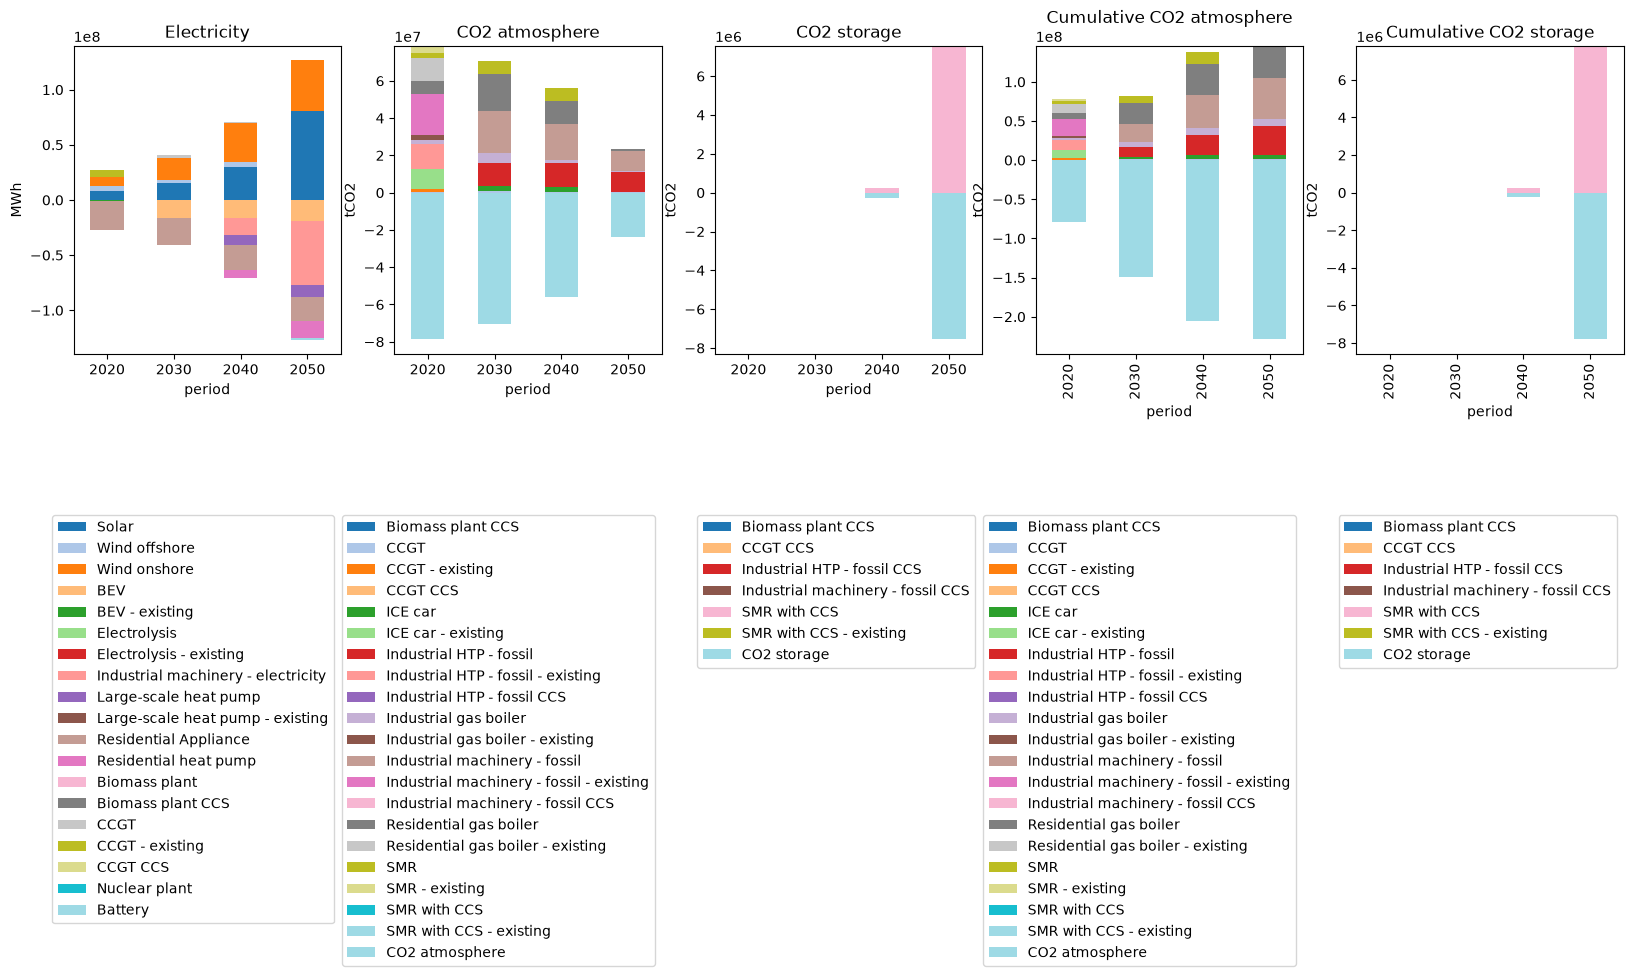

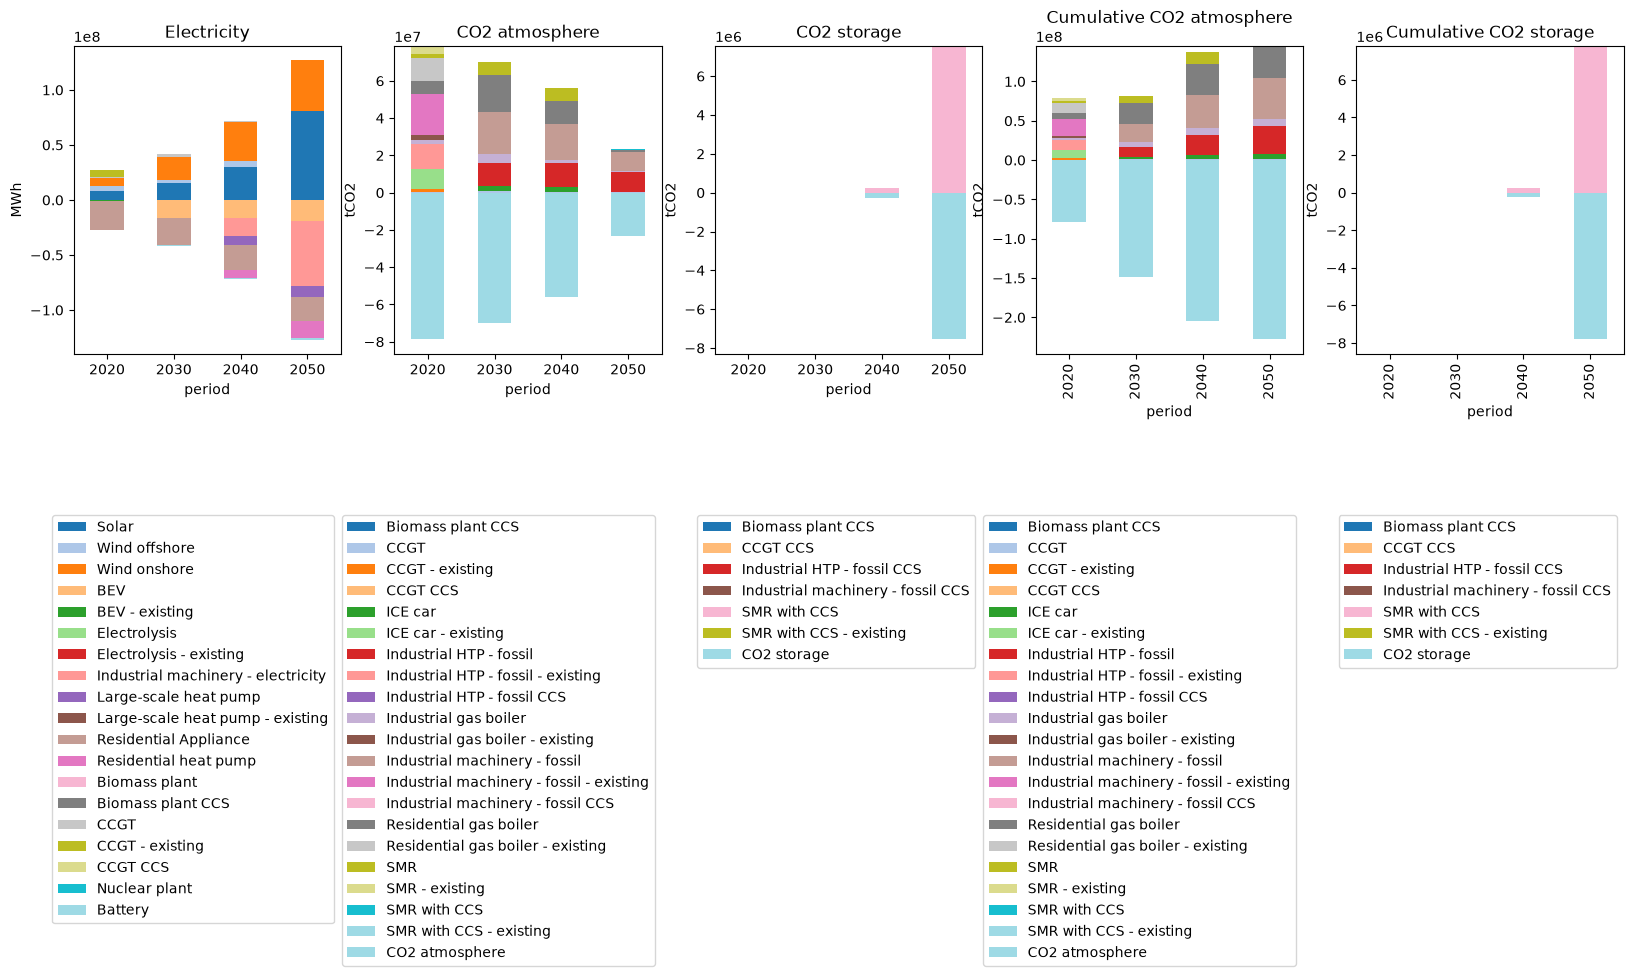

In [21]:
plot_main_ebs_complete(networks['default_tech_low_carbon'])
plot_main_ebs_complete(networks['improved_tech_low_carbon'])
plot_main_ebs_complete(networks['default_tech_high_carbon'])
plot_main_ebs_complete(networks['improved_tech_high_carbon'])

print("default_tech_low_carbon")
plot_elc_emi(networks['default_tech_low_carbon'])
print("improved_tech_low_carbon")
plot_elc_emi(networks['improved_tech_low_carbon'])
print("default_tech_high_carbon")
plot_elc_emi(networks['default_tech_high_carbon'])
print("improved_tech_high_carbon")
plot_elc_emi(networks['improved_tech_high_carbon'])

### 3) Examining industrial low-to-medium heat demand provision

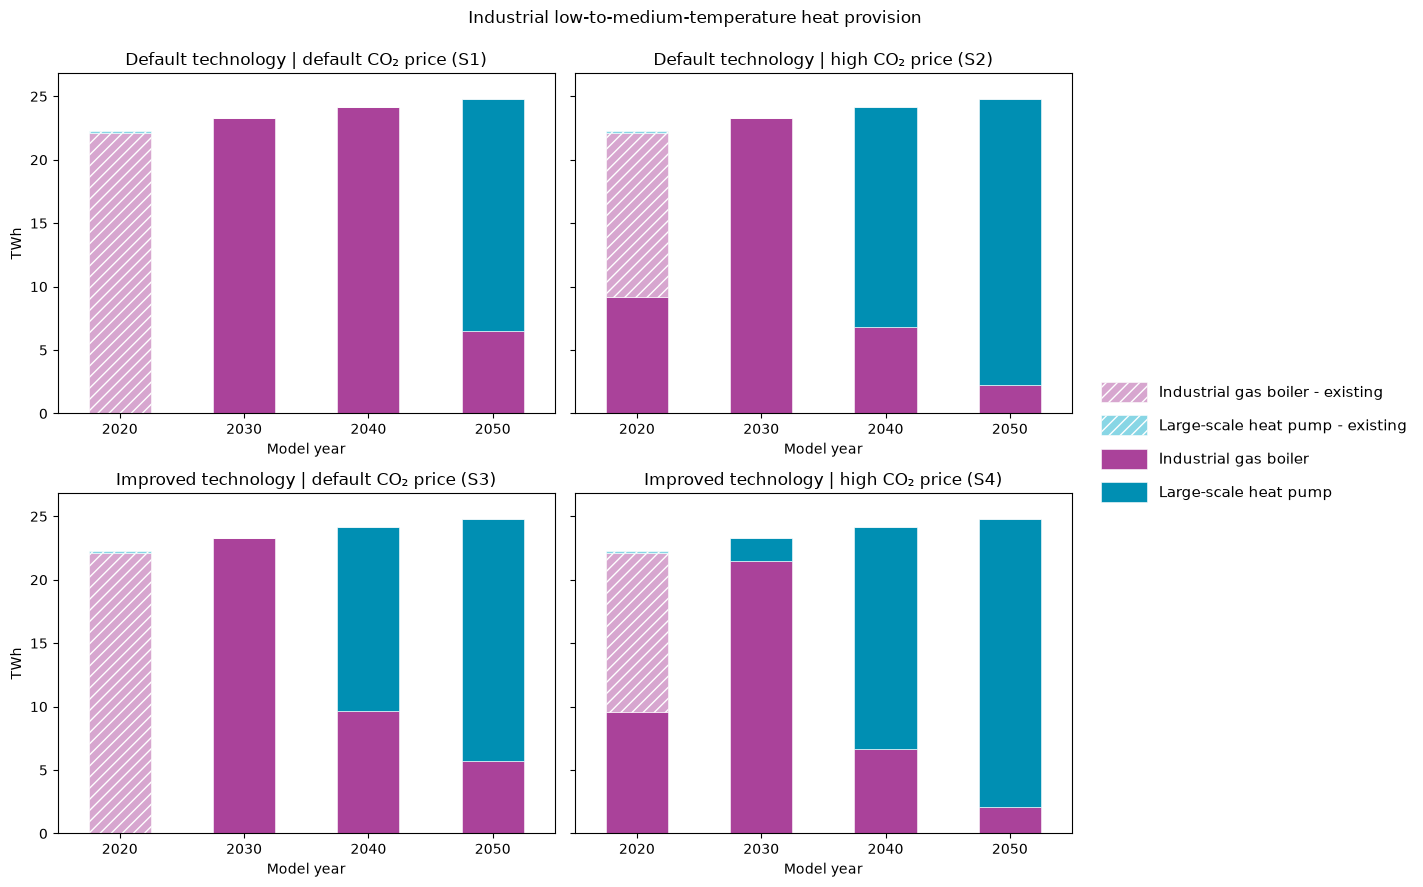

In [ ]:
def plot_ltp_heat(networks, scenarios, labels):
    """Extract annual LTP heat supply and plot four stacked-bar panels."""
    if len(scenarios) != 4:
        raise ValueError("Select exactly four scenarios for the 2×2 chart.")

    # Defaults reproduce the gas-boiler and heat-pump colour convention.
    colors = {
        "Industrial gas boiler": "#AA429A",
        "Industrial gas boiler - existing": "#D7A6CF",
        "Large-scale heat pump": "#008FB3",
        "Large-scale heat pump - existing": "#88D6E5",
    }
    tables = {}

    # 1. Extract heat output, weight by represented hours (t_res=7), and sum by year.
    for scenario in scenarios:
        n = networks[scenario]
        heat_buses = n.buses.index[
            n.buses["carrier"].eq("Industrial LTP")
            | n.buses.index.isin(["Industrial LTP"])
        ]
        carriers = n.links["carrier"].astype(str)
        base_carriers = carriers.str.replace(r" - existing$", "", regex=True)
        links = n.links.index[
            n.links["bus1"].isin(heat_buses)
            & base_carriers.isin([
                "Industrial gas boiler", "Large-scale heat pump"
            ])
        ]
        if links.empty:
            raise ValueError(f"No LTP boilers or heat pumps found in {scenario}.")

        # Delivery to bus1 is negative in PyPSA. MW × hours gives MWh.
        heat = (-n.links_t.p1.loc[:, links]).clip(lower=0).mul(
            n.snapshot_weightings["generators"], axis=0
        )
        heat = heat.T.groupby(carriers.loc[links]).sum().T

        if isinstance(n.snapshots, pd.MultiIndex):
            years = n.snapshots.get_level_values(0)
        elif isinstance(n.snapshots, pd.DatetimeIndex):
            years = n.snapshots.year
        else:
            raise ValueError("Expected multi-period or datetime snapshots.")

        tables[scenario] = heat.groupby(years).sum() / 1e6  # MWh → TWh

    # 2. Use the same technologies, year positions, and y-axis in every panel.
    technologies = sorted({
        c for table in tables.values() for c in table.columns
        if table[c].abs().max() > 1e-8
    })
    if not technologies:
        raise ValueError("No nonzero LTP heat supply to plot.")

    years = sorted({year for table in tables.values() for year in table.index})
    max_supply = max(table.sum(axis=1).max() for table in tables.values())
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)

    for ax, scenario in zip(axes.flat, scenarios):
        table = tables[scenario].reindex(
            index=years, columns=technologies
        ).fillna(0)
        table.plot.bar(
            stacked=True, ax=ax, rot=0, legend=False,
            color=[colors.get(c, "#B0B5BC") for c in technologies],
            edgecolor="white", linewidth=0.4,
        )
        for technology, container in zip(technologies, ax.containers):
            if technology.endswith(" - existing"):
                for bar in container:
                    bar.set_hatch("///")

        ax.set_title(labels[scenario])
        ax.set_xlabel("Model year")
        ax.set_ylabel("TWh")
        ax.set_ylim(0, max_supply * 1.08)  # added so the 2050 bar does not touch the top
        ax.grid(False)

    # 3. Add one shared legend, with existing technologies listed first.
    legend_order = sorted(
        technologies,
        key=lambda c: (not c.endswith(" - existing"), c.lower()),
    )
    fig.legend(
        handles=[
            Patch(
                facecolor=colors.get(c, "#B0B5BC"), edgecolor="white",
                linewidth=0.4,
                hatch="///" if c.endswith(" - existing") else None,
                label=c,
            )
            for c in legend_order
        ],
        loc="center left", bbox_to_anchor=(0.78, 0.5),
        frameon=False,
        fontsize=11,        
        handlelength=3.0,   
        handleheight=1.6,   
        labelspacing=0.9,   
    )
    fig.tight_layout(rect=[0, 0, 0.78, 0.95])  # was 0.82, leaves room for the larger legend
    fig.suptitle("Industrial low-to-medium-temperature heat provision")
    plt.show()
    return fig, axes


# Reuse the loaded networks and scenario labels; produce the chart.
fig, axes = plot_ltp_heat(networks, SCENARIOS, LABELS)

Absolute cumulative direct boiler emissions at final model year (MtCO2):
default_tech_low_carbon      137.156
default_tech_high_carbon      94.026
improved_tech_low_carbon     104.236
improved_tech_high_carbon     89.415

Additional boiler savings from higher carbon pricing (MtCO2):
Default technology     43.130
Improved technology    14.821

Technology-associated boiler savings at fixed carbon price (MtCO2):
Default carbon price    32.920
High carbon price        4.611


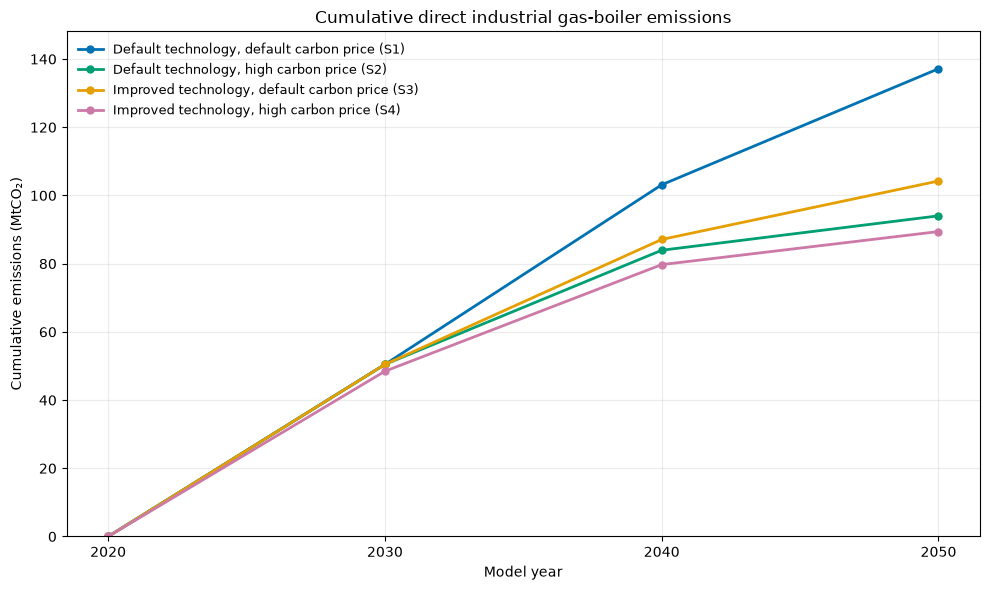

In [50]:
def plot_cumulative_boiler_emissions(networks):
    """Compare direct industrial LTP gas-boiler emissions in four scenarios.

    Requires annual_emissions() and integrate_annual_rates() from the previous
    emissions-contribution code. Uses the same annual weighting and trapezoidal
    integration, with cumulative emissions equal to zero in the first year.
    """
    scenarios = [
        ("default_tech_low_carbon", "Default technology, default carbon price (S1)", "#0072B2", "-"),
        ("default_tech_high_carbon", "Default technology, high carbon price (S2)", "#009E73", "-"),
        ("improved_tech_low_carbon", "Improved technology, default carbon price (S3)", "#E69F00", "-"),
        ("improved_tech_high_carbon", "Improved technology, high carbon price (S4)", "#CC79A7", "-"),
    ]

    annual_series = {}
    cumulative_series = {}
    common_years = None
    for name, label, color, linestyle in scenarios:
        annual = annual_emissions(networks[name])[["Gas boilers"]]
        if common_years is None:
            common_years = annual.index
        elif not annual.index.equals(common_years):
            raise ValueError("All four scenarios must contain the same model years.")
        annual_series[name] = annual["Gas boilers"]
        cumulative_series[name] = integrate_annual_rates(annual)["Gas boilers"]

    annual_results = pd.DataFrame(annual_series)
    cumulative_results = pd.DataFrame(cumulative_series)
    years = common_years.to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=(10, 6))
    for name, label, color, linestyle in scenarios:
        ax.plot(
            years, cumulative_results[name],
            color=color, linestyle=linestyle, marker="o", linewidth=2,
            markersize=5, label=label,
        )

    ax.set_title("Cumulative direct industrial gas-boiler emissions")
    ax.set_xlabel("Model year")
    ax.set_ylabel("Cumulative emissions (MtCO₂)")
    ax.set_xticks(years)
    minimum = min(0.0, cumulative_results.min().min())
    maximum = max(0.0, cumulative_results.max().max())
    padding = 0.08 * (maximum - minimum) if maximum > minimum else 1.0
    ax.set_ylim(minimum - padding if minimum < 0 else 0, maximum + padding)
    ax.grid(True, alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=9)
    fig.tight_layout()

    print("Absolute cumulative direct boiler emissions at final model year (MtCO2):")
    print(cumulative_results.iloc[-1].round(3).to_string())
    print("\nAdditional boiler savings from higher carbon pricing (MtCO2):")
    print(pd.Series({
        "Default technology": (
            cumulative_results["default_tech_low_carbon"].iloc[-1]
            - cumulative_results["default_tech_high_carbon"].iloc[-1]
        ), 
        "Improved technology": (
            cumulative_results["improved_tech_low_carbon"].iloc[-1]
            - cumulative_results["improved_tech_high_carbon"].iloc[-1]
        ),
    }).round(3).to_string())
    print("\nTechnology-associated boiler savings at fixed carbon price (MtCO2):")
    print(pd.Series({
        "Default carbon price": (
            cumulative_results["default_tech_low_carbon"].iloc[-1]
            - cumulative_results["improved_tech_low_carbon"].iloc[-1]
        ),
        "High carbon price": (
            cumulative_results["default_tech_high_carbon"].iloc[-1]
            - cumulative_results["improved_tech_high_carbon"].iloc[-1]
        ),
    }).round(3).to_string())

    plt.show()
    return fig, ax, annual_results, cumulative_results


# Run the earlier emissions-contribution cell first to define
# annual_emissions() and integrate_annual_rates().
fig_boilers, ax_boilers, annual_boiler_emissions, cumulative_boiler_emissions = (
    plot_cumulative_boiler_emissions(networks)
)

Absolute cumulative emissions, 2020–2050 (MtCO2):
      System  Gas boilers
S1  2035.072      137.156
S2  1777.315       94.026
S3  2001.535      104.236
S4  1769.290       89.415

Reductions relative to S1 (technology, pricing, both):
    Total reduction  Direct boiler reduction  Remaining net reduction  Baseline emissions avoided (%)
S3           33.537                   32.920                    0.617                           1.648
S2          257.757                   43.130                  214.628                          12.666
S4          265.782                   47.741                  218.042                          13.060

Combined minus sum of standalone savings: -25.512 MtCO2

Pricing-associated system savings at fixed technology (MtCO2):
Default technology (S1 - S2)     257.757
Improved technology (S3 - S4)    232.245

Interaction interpretation requires the same changed price path in S2 and S4.


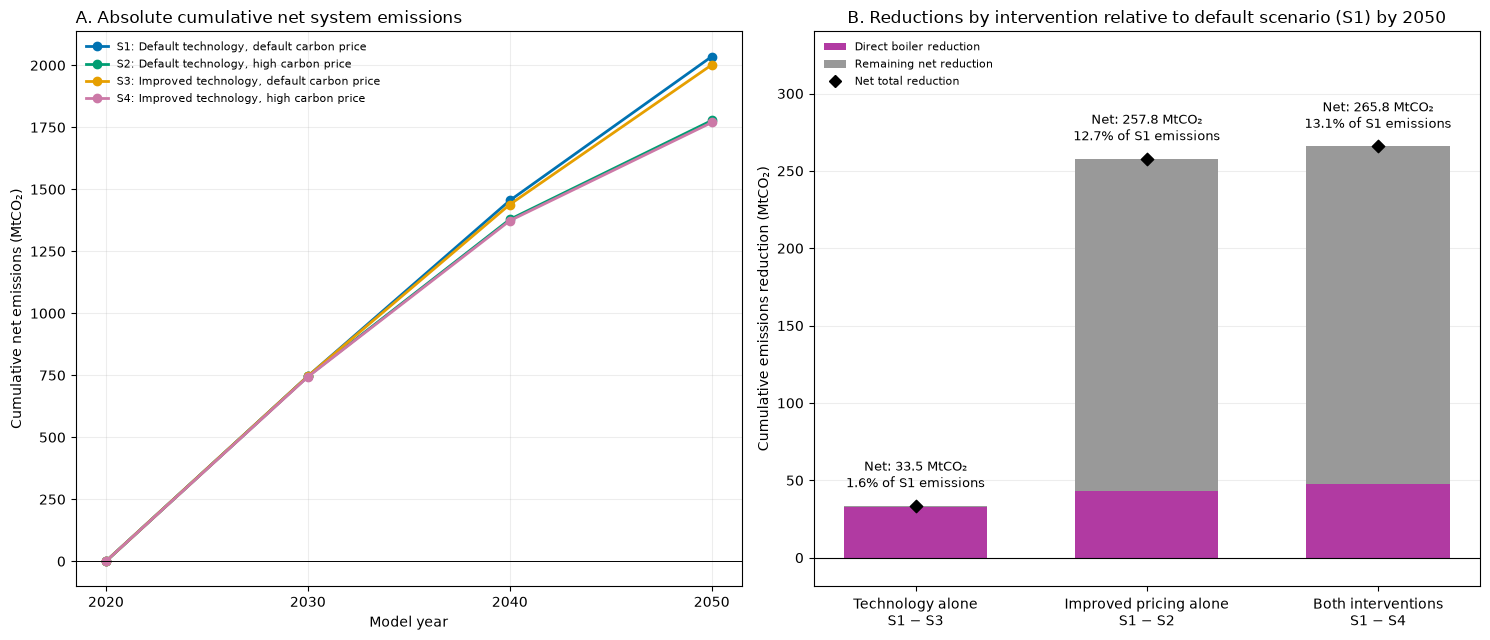

In [75]:
def plot_system_intervention_effects(
    annual_by_scenario,
    system_column="System",
    boiler_column="Gas boilers",
    start_year=None,
    end_year=None,
    save_prefix=None,
):
    """Plot cumulative system emissions and reductions relative to S1.

    Corrected scenario mapping:
      S1: default technology, default carbon price
      S2: default technology, high carbon price
      S3: improved technology, default carbon price
      S4: improved technology, high carbon price

    Input: dictionary of annual-emissions DataFrames indexed by model year.
    Cumulative emissions start at zero in the first selected model year.
    """
    styles = {
        "S1": ("Default technology, default carbon price", "#0072B2", "-"),
        "S2": ("Default technology, high carbon price", "#009E73", "-"),
        "S3": ("Improved technology, default carbon price", "#E69F00", "-"),
        "S4": ("Improved technology, high carbon price", "#CC79A7", "-"),
    }
    annual = {}
    common_years = None
    for scenario in styles:
        if scenario not in annual_by_scenario:
            raise KeyError(f"Missing scenario {scenario}.")
        source = annual_by_scenario[scenario].copy()
        missing = [c for c in (system_column, boiler_column) if c not in source.columns]
        if missing:
            raise ValueError(
                f"{scenario}: missing columns {missing}. Available columns: "
                f"{list(source.columns)}. Set system_column and boiler_column "
                "to the appropriate annual-emissions column names."
            )
        table = source[[system_column, boiler_column]].astype(float)
        table.index = pd.Index(pd.to_numeric(table.index), name="Model year")
        table = table.sort_index()
        if table.index.has_duplicates:
            raise ValueError(f"{scenario}: duplicate model years.")
        if start_year is not None:
            if start_year not in table.index:
                raise ValueError(f"{scenario}: start_year must be a model year.")
            table = table.loc[table.index >= start_year]
        if end_year is not None:
            if end_year not in table.index:
                raise ValueError(f"{scenario}: end_year must be a model year.")
            table = table.loc[table.index <= end_year]
        if len(table) < 2 or not np.isfinite(table.to_numpy()).all():
            raise ValueError(f"{scenario}: need at least two years and finite rates.")
        if common_years is None:
            common_years = table.index
        elif not table.index.equals(common_years):
            raise ValueError("All scenarios must have identical model years.")
        annual[scenario] = table

    years = common_years.to_numpy(dtype=float)
    cumulative = {}
    for scenario, table in annual.items():
        rates = table.to_numpy()
        increments = (rates[:-1] + rates[1:]) * 0.5 * np.diff(years)[:, None]
        integrated = np.vstack([np.zeros((1, 2)), np.cumsum(increments, axis=0)])
        cumulative[scenario] = pd.DataFrame(
            integrated, index=common_years, columns=[system_column, boiler_column]
        )

    final = pd.DataFrame({s: t.iloc[-1] for s, t in cumulative.items()}).T
    baseline = final.loc["S1", system_column]
    # Order the bars as technology alone, pricing alone, both together.
    effects = pd.DataFrame(index=["S3", "S2", "S4"])
    effects["Total reduction"] = baseline - final.loc[effects.index, system_column]
    effects["Direct boiler reduction"] = (
        final.loc["S1", boiler_column] - final.loc[effects.index, boiler_column]
    )
    effects["Remaining net reduction"] = (
        effects["Total reduction"] - effects["Direct boiler reduction"]
    )
    effects["Baseline emissions avoided (%)"] = (
        100 * effects["Total reduction"] / baseline if baseline > 0 else np.nan
    )
    interaction = (
        effects.loc["S4", "Total reduction"]
        - effects.loc["S3", "Total reduction"]
        - effects.loc["S2", "Total reduction"]
    )

    fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(15, 6.5))
    for scenario, (label, color, linestyle) in styles.items():
        ax_a.plot(
            years, cumulative[scenario][system_column], color=color,
            linestyle=linestyle, marker="o", linewidth=2,
            label=f"{scenario}: {label}",
        )
    ax_a.set_title("A. Absolute cumulative net system emissions", loc="left")
    ax_a.set_xlabel("Model year")
    ax_a.set_ylabel("Cumulative net emissions (MtCO₂)")
    ax_a.set_xticks(years)
    ax_a.axhline(0, color="black", linewidth=0.7)
    ax_a.grid(True, alpha=0.22)
    ax_a.set_axisbelow(True)
    ax_a.legend(frameon=False, fontsize=8, loc="best")

    x = np.arange(3)
    components = [
        ("Direct boiler reduction", "#B13AA2"),
        ("Remaining net reduction", "#999999"),
    ]
    positive_bottom = np.zeros(3)
    negative_bottom = np.zeros(3)
    for column, color in components:
        values = effects[column].to_numpy(dtype=float)
        bottoms = np.where(values >= 0, positive_bottom, negative_bottom)
        ax_b.bar(x, values, bottom=bottoms, width=0.62, color=color)
        positive_bottom += np.maximum(values, 0)
        negative_bottom += np.minimum(values, 0)

    totals = effects["Total reduction"].to_numpy(dtype=float)
    ax_b.scatter(x, totals, marker="D", s=40, color="black", zorder=4)
    span = max(float(positive_bottom.max() - negative_bottom.min()), 1.0)
    for i, scenario in enumerate(effects.index):
        pct = effects.loc[scenario, "Baseline emissions avoided (%)"]
        label = f"Net: {totals[i]:.1f} MtCO₂"
        if np.isfinite(pct):
            label += f"\n{pct:.1f}% of S1 emissions"
        ax_b.text(x[i], positive_bottom[i] + 0.035 * span, label,
                  ha="center", va="bottom", fontsize=9)
    ax_b.set_ylim(negative_bottom.min() - 0.07 * span,
                  positive_bottom.max() + 0.28 * span)
    ax_b.set_xticks(x)
    ax_b.set_xticklabels([
        "Technology alone\nS1 − S3",
        "Improved pricing alone\nS1 − S2",
        "Both interventions\nS1 − S4",
    ])
    ax_b.set_title(f"B. Reductions by intervention relative to default scenario (S1) by 2050")
    ax_b.set_ylabel("Cumulative emissions reduction (MtCO₂)")
    ax_b.axhline(0, color="black", linewidth=0.8)
    ax_b.grid(axis="y", alpha=0.22)
    ax_b.set_axisbelow(True)
    handles = [Patch(facecolor=color, label=name) for name, color in components]
    handles.append(plt.Line2D([0], [0], color="black", marker="D",
                              linestyle="None", label="Net total reduction"))
    ax_b.legend(handles=handles, frameon=False, fontsize=8, loc="upper left")

    fig.tight_layout()
    if save_prefix:
        fig.savefig(f"{save_prefix}.png", dpi=300, bbox_inches="tight")
        fig.savefig(f"{save_prefix}.pdf", bbox_inches="tight")
        effects.to_csv(f"{save_prefix}_reductions.csv")
        final.to_csv(f"{save_prefix}_absolute_emissions.csv")

    print(f"Absolute cumulative emissions, {years[0]:g}–{years[-1]:g} (MtCO2):")
    print(final.round(3).to_string())
    print("\nReductions relative to S1 (technology, pricing, both):")
    print(effects.round(3).to_string())
    print(f"\nCombined minus sum of standalone savings: {interaction:.3f} MtCO2")
    print("\nPricing-associated system savings at fixed technology (MtCO2):")
    print(pd.Series({
        "Default technology (S1 - S2)": final.loc["S1", system_column] - final.loc["S2", system_column],
        "Improved technology (S3 - S4)": final.loc["S3", system_column] - final.loc["S4", system_column],
    }).round(3).to_string())
    print("\nInteraction interpretation requires the same changed price path in S2 and S4.")
    plt.show()
    return fig, (ax_a, ax_b), cumulative, effects, final


# Run your earlier extraction cell first to define annual_emissions().
# The underlying network keys are unchanged; only scenario numbering changes.
annual_by_scenario = {
    "S1": annual_emissions(networks["default_tech_low_carbon"]),
    "S2": annual_emissions(networks["default_tech_high_carbon"]),
    "S3": annual_emissions(networks["improved_tech_low_carbon"]),
    "S4": annual_emissions(networks["improved_tech_high_carbon"]),
}

fig_system, axes_system, cumulative_system, intervention_effects, final_emissions = (
    plot_system_intervention_effects(
        annual_by_scenario,
        system_column="System",  # Set to the actual NET system-emissions column name.
        boiler_column="Gas boilers",
        save_prefix=None,  # Set a filename prefix to export PNG, PDF and CSVs.
    )
)
